In [1]:
# importing all libraries 
import numpy as np
import matplotlib.pyplot as plt
import tifffile 

"""One volume -> one parameter pair"""

In [2]:
# Connect to dropbox database 
from pathlib import Path
folder = Path("C:\\Users\\issyh\\Downloads\\sensitivity_chunk_IC_768")
folder = folder / "sensitivity_chunk_IC_768"
folder.exists()

True

In [3]:
# Check for paths of files in folder and length of files to be 768 (items)
files = sorted(folder.glob('*.tif'))
print(len(files))
print(files[:2])

768
[WindowsPath('C:/Users/issyh/Downloads/sensitivity_chunk_IC_768/sensitivity_chunk_IC_768/cst_slab_7680000.tif'), WindowsPath('C:/Users/issyh/Downloads/sensitivity_chunk_IC_768/sensitivity_chunk_IC_768/cst_slab_7680001.tif')]


In [4]:
# Test tiffile.imread on first file and check for its shape and dtype
img = tifffile.imread(files[0])
print(img.shape, img.dtype)

(767, 768) uint8


In [5]:
# Read all the slices and stack them into a 3D array
slices = []
for f in files:
    img = tifffile.imread(f)
    slices.append(img)

# Important: stacked slices into a 3D array
volume = np.stack(slices)

print(volume.shape, volume.dtype)

(768, 767, 768) uint8


"Visualisations of selected slice"

In [6]:
# Truncate volume (lack of RAM) to (256, 256, 256)
def truncate(vol, start, finish):
    vol = volume 
    return vol[start:finish, start:finish, start:finish]

volume_small = truncate(volume, 125, 250)  # 128^3; widen for the full cube

# Check for new truncated volume shape and dtype
print(volume_small.shape, volume_small.dtype) 

(125, 125, 125) uint8


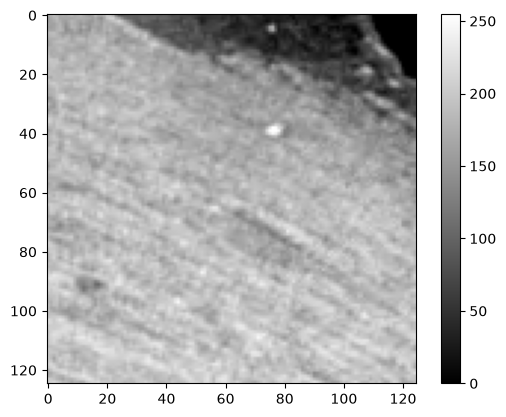

''

In [7]:
# Display grascale image of one slice from the truncated volume
def get_volume_shape(vol):
    """Report valid slice index range along each axis."""
    return vol.shape  # (z, y, x) as magnitudes of axis size from axis (0, 1, 2) from stacking

def show_raw_slice(vol, index, axis=0):
    """Extract and display one slice as grayscale."""
    slicer = [slice(None)] * vol.ndim # builds [:, :, :]
    slicer[axis] = index # becomes [:, :, index] for axis=2, for example
    slice_data = vol[tuple(slicer)]

    # Display grascale image of selected slice 
    plt.imshow(slice_data, cmap='gray')
    plt.colorbar()
    plt.show()
    return slice_data

# Example usage
show_raw_slice(volume_small, index = 80, axis = 0)  # Display slice along z-axis at index 128 for middle slice
;

In [8]:
# Overarching function call for eigendecomp and rgb and fa
# DTU notes on eigendecomp could be useful 

import numpy as np

# DLI restrictions 
try:
    from structure_tensor import eig_special_3d, structure_tensor_3d
except ImportError as e:
    print("structure_tensor import failed:", e)
    from scipy.ndimage import gaussian_filter

    def structure_tensor_3d(volume, sigma, rho):
        vol = gaussian_filter(volume.astype(np.float32), sigma=sigma)
        gx, gy, gz = np.gradient(vol)

        Jxx = gaussian_filter(gx * gx, sigma=rho)
        Jyy = gaussian_filter(gy * gy, sigma=rho)
        Jzz = gaussian_filter(gz * gz, sigma=rho)
        Jxy = gaussian_filter(gx * gy, sigma=rho)
        Jxz = gaussian_filter(gx * gz, sigma=rho)
        Jyz = gaussian_filter(gy * gz, sigma=rho)

        return np.stack((Jxx, Jyy, Jzz, Jxy, Jxz, Jyz))

    def eig_special_3d(S):
        Jxx, Jyy, Jzz, Jxy, Jxz, Jyz = S
        z, y, x = Jxx.shape

        val = np.empty((3, z, y, x), dtype=np.float32)
        vec = np.empty((3, z, y, x), dtype=np.float32)

        for k in range(z):
            n = y * x
            mat = np.empty((n, 3, 3), dtype=np.float32)
            mat[:, 0, 0] = Jxx[k].ravel()
            mat[:, 1, 1] = Jyy[k].ravel()
            mat[:, 2, 2] = Jzz[k].ravel()
            mat[:, 0, 1] = mat[:, 1, 0] = Jxy[k].ravel()
            mat[:, 0, 2] = mat[:, 2, 0] = Jxz[k].ravel()
            mat[:, 1, 2] = mat[:, 2, 1] = Jyz[k].ravel()

            w, v = np.linalg.eigh(mat)
            val[:, k] = w.T.reshape(3, y, x)
            vec[:, k] = v[:, :, 2].T.reshape(3, y, x)

        return val, vec

# val and vec both have shape [3, 256, 256, 256]
# val[:, i, j, k] = eigenvalues at voxel (i, j, k)
# vec[:, i, j, k] = eigenvectors at voxel (i, j, k)

def compute_fa(val):
    lambda_mean = val.mean(axis=0) 
    
    numerator = ((val[0] - lambda_mean)**2 +
                 (val[1] - lambda_mean)**2 +
                 (val[2] - lambda_mean)**2)
    
    denominator = val[0]**2 + val[1]**2 + val[2]**2
    
    # Compute FA only when denominator is non-zero 
    fa = np.zeros_like(denominator)
    mask = denominator > 0
    fa[mask] = np.sqrt(1.5 * (numerator[mask] / denominator[mask]))

    # Replace NaN, -inf and +inf values with 0.0
    return np.nan_to_num(fa, nan=0.0, neginf=0.0, posinf=0.0)

def compute_rgb(vec):
    # colour maps only to direction not sign, same fibre
    rgb = np.abs(vec)
    rgb = np.nan_to_num(rgb, nan=0.0)
    
    # divide by global max so brightest component displays as white (1)
    max_val = rgb.max()
    if max_val > 0:
        rgb = rgb / max_val
    
    # convert to image format 0-255 not 0-1 floats
    rgb = (rgb * 255).astype(np.uint8)
    
    return rgb

def run_structure_tensor(volume, sigma, rho):
    # for volume with shae (x, y, x), vec in form zyx, val in form zyx
    S = structure_tensor_3d(volume.astype(np.float32), sigma, rho)
    val, vec = eig_special_3d(S) 
    
    # apply above functions to compute fa and rgb
    fa = compute_fa(val)
    rgb = compute_rgb(vec)

    return val, vec, fa, rgb

def show_slice(fa, rgb, index, axis=0):
    fa_slice = fa[index]
    rgb_slice = np.moveaxis(rgb[:, index], 0, -1) # plt.imshow expects (height, width, 3), move 3 to last axis

    print("inside show_slice:", rgb_slice.max(), rgb_slice.dtype)

    plt.imshow(fa_slice, cmap='gray')
    plt.colorbar()
    plt.show()

    plt.imshow(rgb_slice)
    plt.colorbar()
    plt.show()

    return fa_slice, rgb_slice
;

''

In [14]:
# More example run throughs with different indices

volume_small = truncate(volume, 299, 496) 

def see_visualisations(volume, index, sigma, rho): 
    # ray greyscale slice
    show_raw_slice(volume, index, axis=0)  

    # compute structure tensors and show FA/RGB
    val, vec, fa, rgb = run_structure_tensor(volume, sigma, rho)
    show_slice(fa, rgb, index)

see_visualisations(volume=volume_small, index=196, sigma=0.5 rho=4.5)

SyntaxError: invalid syntax. Perhaps you forgot a comma? (546183023.py, line 13)

In [12]:
# Convert to NIfTI format using NiBabel 
import numpy as np
import nibabel as nib

# Set numpy to print only 2 decimal digits for neatness
np.set_printoptions(precision=2, suppress=True)

# Create affine matrix for 768 px. volume of 20 micrometers/voxel, subject i74
affine = np.diag([0.02, 0.020, 0.020, 1.0])
print(affine)

img = nib.Nifti1Image(fa, affine)
nib.save(img, 'fa_i74.nii.gz')

[[0.02 0.   0.   0.  ]
 [0.   0.02 0.   0.  ]
 [0.   0.   0.02 0.  ]
 [0.   0.   0.   1.  ]]


NameError: name 'fa' is not defined

In [ ]:
import os
print(os.getcwd())